In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set visual style for seaborn charts
sns.set_theme(style='whitegrid')
print('Libraries imported successfully!')

Libraries imported successfully!


In [6]:
# Load the dataset
df = pd.read_csv('student_survey_data.csv')

# Inspect the first few rows and dimensions
print(f'Dataset Shape: {df.shape}')
display(df.head())

Dataset Shape: (1000, 22)


,Respondent_ID,Sex,Grade_Level,General_Average,Monthly_Household_Income,Caregiver_Education,Primary_Internet_Access,SH1_Set_Daily_Study_Time,SH2_Complete_Assignments_On_Time,SH3_Prepare_Exams_In_Advance,...,SH6_Take_and_Review_Notes,SH7_Ask_Questions_Clarifications,SF1_Parental_Encouragement,SF2_Family_Learning_Materials,SF3_Peer_Academic_Help,SF4_Peer_Motivation,SF5_Access_to_Tutors,SF6_Tutorial_Session_Effectiveness,SF7_Teacher_Accessibility,SF8_School_Facilities
0,RESP-0001,Male,Grade 7,75%-79% (Fairly Satisfactory / Passing Class),"Below 10,000",High School Level / Graduate,Mobile Data,1,3,1,...,3,4,2,2,2,4,2,3,1,3
1,RESP-0002,Female,Grade 9,Below 75% (Did Not Meet Expectations),"Below 10,000",College Level / Graduate,Mobile Data,3,1,3,...,1,3,3,2,3,3,2,3,2,4
2,RESP-0003,Female,Grade 10,85%-89% (Very Satisfactory / High Class),"P20,001-P40,000",High School Level / Graduate,Mobile Data,3,3,3,...,2,3,3,2,3,4,2,3,3,4
3,RESP-0004,Female,Grade 9,90% and above (Outstanding / Outstanding Class),"Below 10,000",High School Level / Graduate,Broadband / Wi-Fi,4,4,4,...,3,3,3,3,3,3,3,4,3,3
4,RESP-0005,Male,Grade 10,85%-89% (Very Satisfactory / High Class),"Below 10,000",High School Level / Graduate,Broadband / Wi-Fi,3,3,3,...,3,4,3,3,3,3,3,3,4,3


In [8]:
# 1. Inspect and remove duplicates
initial_rows = len(df)
df = df.drop_duplicates()
print(f'Removed {initial_rows - len(df)} duplicate rows.')

# 2. Inspect missing values
print('Missing values count:', df.isnull().sum().sum())

# Optional: Handle missing values cleanly without FutureWarning
for col in df.select_dtypes(include=['float64', 'int64']).columns:
  df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include=['object']).columns:
  df[col] = df[col].fillna(df[col].mode()[0])

# 3. Format corrections (casting Likert-scale items to integers)
likert_cols = [
    'SH1_Set_Daily_Study_Time',
    'SH2_Complete_Assignments_On_Time',
    'SH3_Prepare_Exams_In_Advance',
    'SH4_Avoid_Social_Media_Distractions',
    'SH5_Quiet_Study_Space',
    'SH6_Take_and_Review_Notes',
    'SH7_Ask_Questions_Clarifications',
    'SF1_Parental_Encouragement',
    'SF2_Family_Learning_Materials',
    'SF3_Peer_Academic_Help',
    'SF4_Peer_Motivation',
    'SF5_Access_to_Tutors',
    'SF6_Tutorial_Session_Effectiveness',
    'SF7_Teacher_Accessibility',
    'SF8_School_Facilities',
]

for col in likert_cols:
  if col in df.columns:
    df[col] = df[col].astype(int)

print('Data cleaning and formatting completed successfully.')

Removed 0 duplicate rows.
Missing values count: 0
Data cleaning and formatting completed successfully.


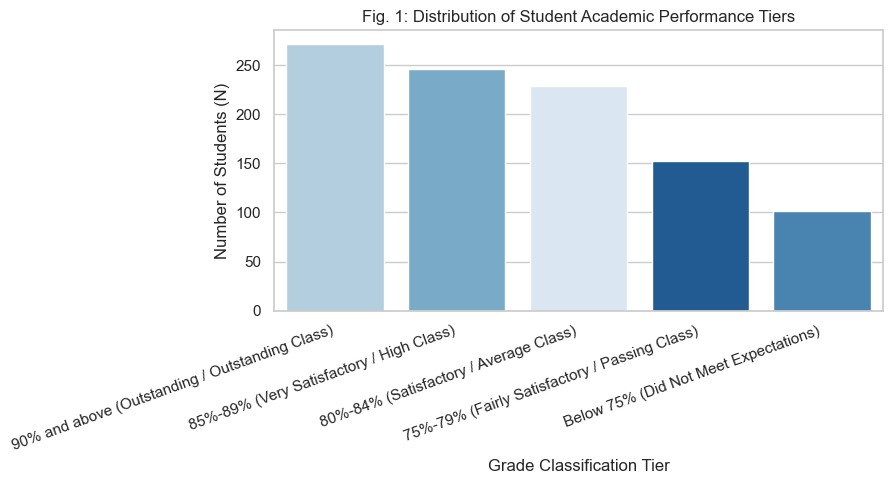

In [12]:
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x='General_Average',
    hue='General_Average',  # Added to prevent Seaborn palette warning
    palette='Blues_r',
    legend=False,
    order=[
        '90% and above (Outstanding / Outstanding Class)',
        '85%-89% (Very Satisfactory / High Class)',
        '80%-84% (Satisfactory / Average Class)',
        '75%-79% (Fairly Satisfactory / Passing Class)',
        'Below 75% (Did Not Meet Expectations)',
    ],
)
plt.title('Fig. 1: Distribution of Student Academic Performance Tiers')
plt.xlabel('Grade Classification Tier')
plt.ylabel('Number of Students (N)')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig('fig1_class_distribution.png', dpi=300)
plt.show()

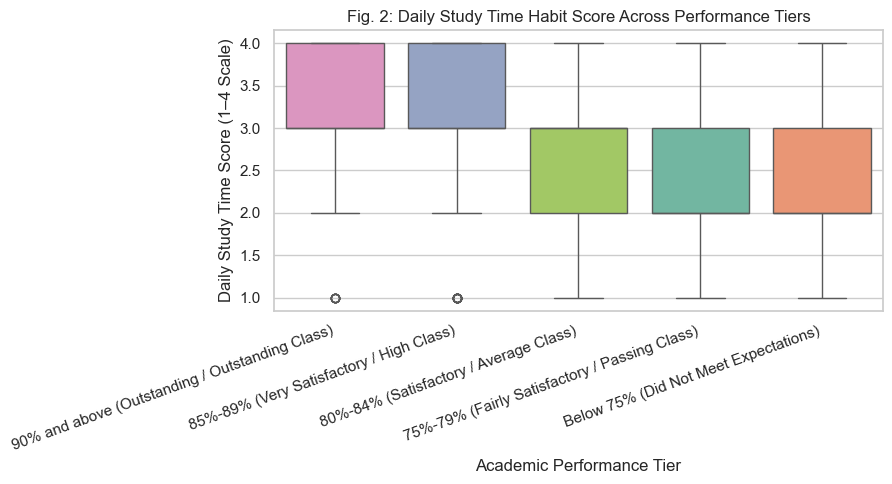

In [17]:
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df,
    x='General_Average',
    y='SH1_Set_Daily_Study_Time',
    hue='General_Average',  # Added to prevent Seaborn palette warning
    palette='Set2',
    legend=False,
    order=[
        '90% and above (Outstanding / Outstanding Class)',
        '85%-89% (Very Satisfactory / High Class)',
        '80%-84% (Satisfactory / Average Class)',
        '75%-79% (Fairly Satisfactory / Passing Class)',
        'Below 75% (Did Not Meet Expectations)',
    ],
)
plt.title('Fig. 2: Daily Study Time Habit Score Across Performance Tiers')
plt.xlabel('Academic Performance Tier')
plt.ylabel('Daily Study Time Score (1–4 Scale)')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig('fig2_study_time_boxplot.png', dpi=300)
plt.show()

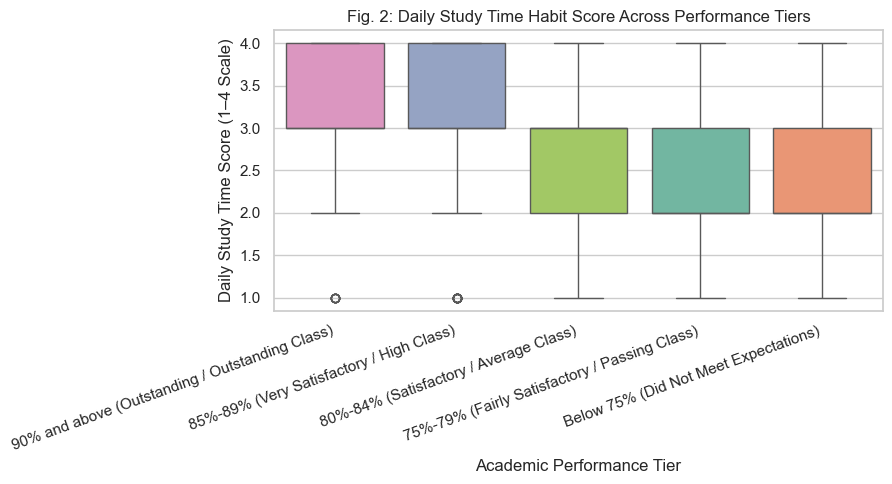

In [18]:
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df,
    x='General_Average',
    y='SH1_Set_Daily_Study_Time',
    hue='General_Average',
    palette='Set2',
    legend=False,
    order=[
        '90% and above (Outstanding / Outstanding Class)',
        '85%-89% (Very Satisfactory / High Class)',
        '80%-84% (Satisfactory / Average Class)',
        '75%-79% (Fairly Satisfactory / Passing Class)',
        'Below 75% (Did Not Meet Expectations)',
    ],
)
plt.title('Fig. 2: Daily Study Time Habit Score Across Performance Tiers')
plt.xlabel('Academic Performance Tier')
plt.ylabel('Daily Study Time Score (1–4 Scale)')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig('fig2_study_time_boxplot.png', dpi=300)
plt.show()

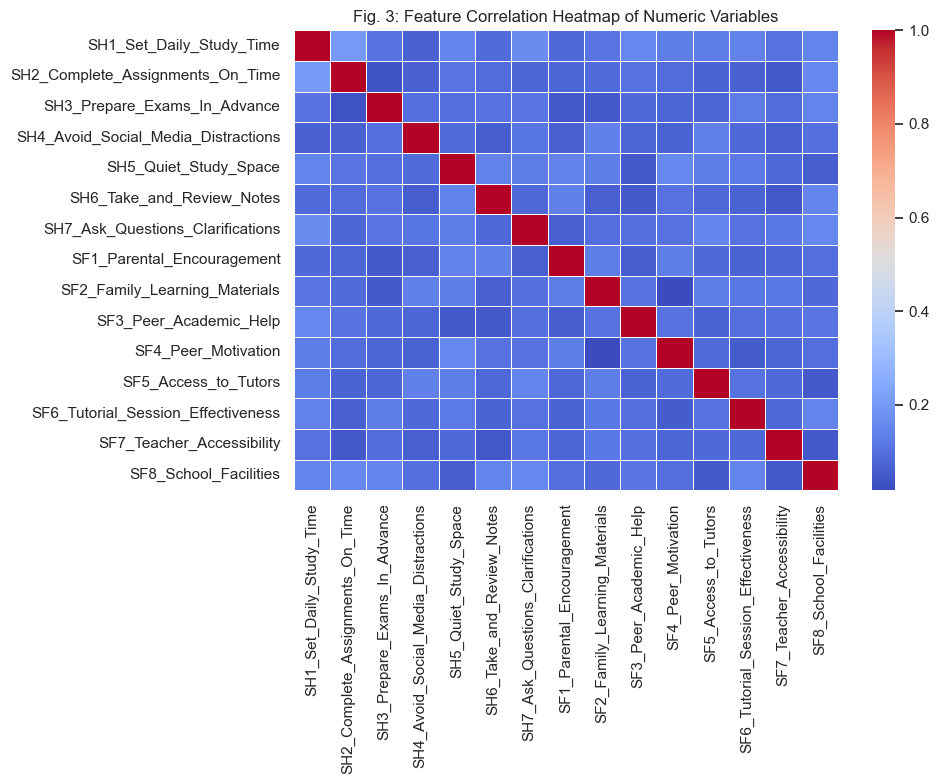

In [19]:
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=['int64', 'float64'])
corr_matrix = numeric_df.corr()
sns.heatmap(
    corr_matrix,
    annot=False,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    cbar=True,
)
plt.title('Fig. 3: Feature Correlation Heatmap of Numeric Variables')
plt.tight_layout()
plt.savefig('fig3_correlation_heatmap.png', dpi=300)
plt.show()

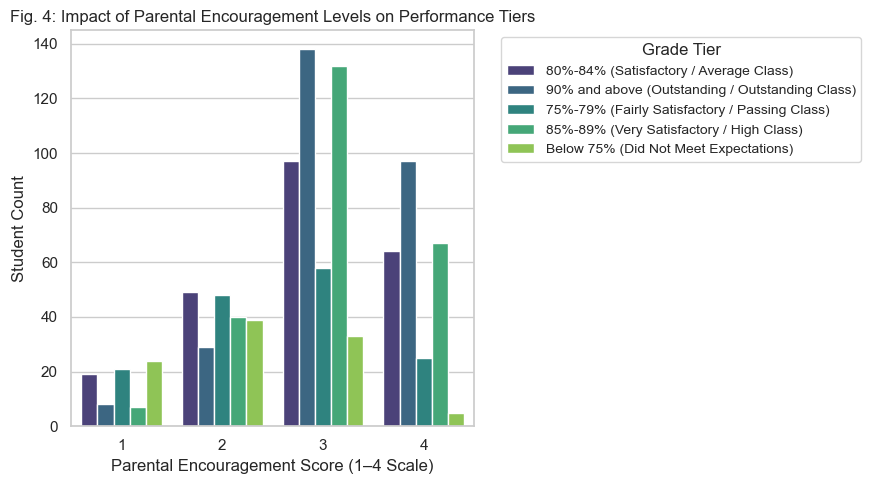

In [20]:
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x='SF1_Parental_Encouragement',
    hue='General_Average',
    palette='viridis',
)
plt.title('Fig. 4: Impact of Parental Encouragement Levels on Performance Tiers')
plt.xlabel('Parental Encouragement Score (1–4 Scale)')
plt.ylabel('Student Count')
plt.legend(
    title='Grade Tier',
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    fontsize='small',
)
plt.tight_layout()
plt.savefig('fig4_parental_support.png', dpi=300)
plt.show()

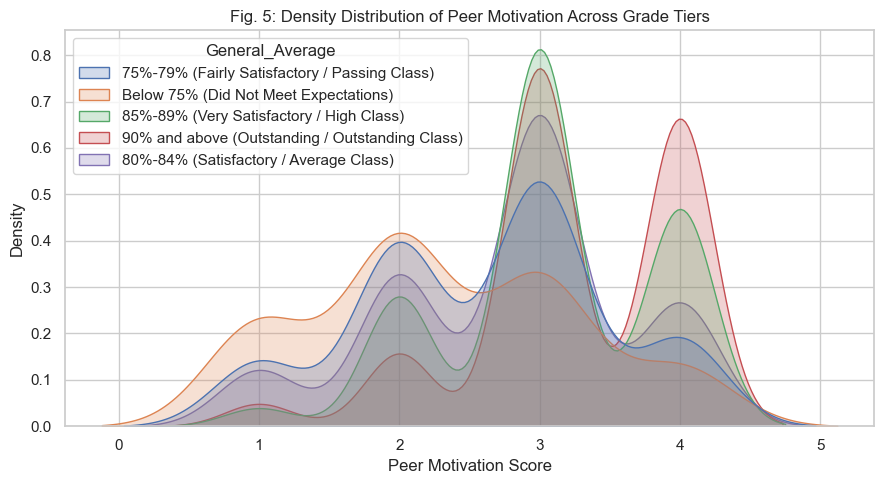

In [21]:
plt.figure(figsize=(9, 5))
sns.kdeplot(
    data=df,
    x='SF4_Peer_Motivation',
    hue='General_Average',
    common_norm=False,
    fill=True,
)
plt.title('Fig. 5: Density Distribution of Peer Motivation Across Grade Tiers')
plt.xlabel('Peer Motivation Score')
plt.ylabel('Density')
plt.tight_layout()
plt.savefig('fig5_peer_motivation_kde.png', dpi=300)
plt.show()

In [22]:
from sklearn.preprocessing import StandardScaler

# 1. Create composite interaction features
study_habit_cols = [col for col in df.columns if col.startswith('SH')]
support_factor_cols = [col for col in df.columns if col.startswith('SF')]

df['Study_Habit_Mean'] = df[study_habit_cols].mean(axis=1)
df['Support_Factor_Mean'] = df[support_factor_cols].mean(axis=1)

# 2. One-Hot Encoding for categorical demographics
cat_cols = [
    'Sex',
    'Grade_Level',
    'Monthly_Household_Income',
    'Caregiver_Education',
    'Primary_Internet_Access',
]
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

# 3. Standardize numeric features
scaler = StandardScaler()
num_cols = df_encoded.select_dtypes(
    include=['float64', 'int64']
).columns.drop(['Respondent_ID'], errors='ignore')

print('Feature engineering and encoding completed successfully!')
print(f'Processed dataset shape: {df_encoded.shape}')
display(df_encoded[['Study_Habit_Mean', 'Support_Factor_Mean']].head())

Feature engineering and encoding completed successfully!
Processed dataset shape: (1000, 32)


,Study_Habit_Mean,Support_Factor_Mean
0,2.714286,2.375
1,2.000000,2.750
2,3.000000,3.000
3,3.428571,3.125
4,3.000000,3.125
